# **Analyse statistique des attributs des chansons sur Spotify : étude de la popularité**

In [47]:
# Bibliothèques standards
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objs as go

# Machine learning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Évaluation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve

# Préparation des données
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer, RobustScaler, MinMaxScaler

# Statistiques
from scipy.stats import chi2_contingency, f_oneway


# **1. Introduction**

La popularité d’une chanson est un phénomène complexe influencé par divers facteurs musicaux et contextuels. Grâce aux vastes quantités de données collectées par Spotify, il est possible d’analyser les attributs des chansons afin de mieux comprendre les éléments qui contribuent à leur succès.  

Ce projet vise à explorer les relations entre différents attributs musicaux (tempo, danseabilité, énergie, tonalité, etc.) et la popularité des chansons. L’analyse s’appuiera sur des statistiques descriptives, des visualisations graphiques et des modèles prédictifs.

L’objectif est d’identifier les caractéristiques clés qui influencent le plus la popularité des morceaux et d’évaluer la performance de modèles prédictifs dans ce contexte. Les résultats obtenus pourront offrir des insights pertinents pour les artistes, producteurs et plateformes de streaming souhaitant optimiser la diffusion et le succès de leur musique.

# **2. Chargement et exploration du dataset**

### **2.1. Chargement**

In [49]:
df = pd.read_csv("dataset.csv",index_col=None)
df.sample(n=5)

,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,target,song_title,artist
600,0.42300,0.786,267160,0.525,0.46100,1,0.0876,-8.271,0,0.0388,128.014,4,0.430,1,Borderline,Classixx
1840,0.10600,0.677,152333,0.437,0.00000,4,0.0897,-7.413,1,0.0322,108.054,4,0.455,0,"When Will My Life Begin - From ""Tangled""/Sound...",Mandy Moore
1964,0.00513,0.685,267947,0.948,0.00347,9,0.1700,-5.182,1,0.0457,104.881,4,0.627,0,MMMBop,Hanson
634,0.14000,0.525,291162,0.538,0.11700,11,0.0950,-9.366,0,0.0783,175.953,4,0.791,1,Get Free (feat. Amber of Dirty Projectors),Major Lazer
1010,0.00298,0.545,278227,0.904,0.00117,6,0.0679,-5.201,1,0.3400,139.871,4,0.681,1,3 Wheel-ups (feat. Wiley & Giggs),Kano


Le tableau ci-dessous présente les variables utilisées dans l'analyse des chansons ainsi que leurs descriptions et types.

| **Nom de la variable**   | **Description**                                                                 | **Type**                |
|--------------------------|---------------------------------------------------------------------------------|-------------------------|
| **acousticness**          | Niveau d’acoustique d’une chanson (valeur entre 0 et 1)                         | Numérique (float)       |
| **danceability**          | Mesure de la facilité à danser sur la chanson (0 à 1)                            | Numérique (float)       |
| **duration_ms**           | Durée de la chanson en millisecondes                                            | Numérique (int)         |
| **energy**                | Niveau d’énergie de la chanson (0 à 1)                                          | Numérique (float)       |
| **instrumentalness**      | Probabilité que la chanson soit instrumentale (0 à 1)                           | Numérique (float)       |
| **key**                   | Tonalité de la chanson (0 = Do, 1 = Do#, ..., 11 = Si)                         | Catégorielle (int)      |
| **liveness**              | Probabilité que la chanson ait été enregistrée en live (0 à 1)                 | Numérique (float)       |
| **loudness**              | Niveau sonore moyen en décibels (dB)                                            | Numérique (float)       |
| **mode**                  | Mode de la chanson (0 = mineur, 1 = majeur)                                     | Catégorielle (int)      |
| **speechiness**           | Présence de paroles parlées dans la chanson (0 à 1)                             | Numérique (float)       |
| **tempo**                 | Tempo de la chanson en battements par minute (BPM)                              | Numérique (float)       |
| **time_signature**        | Mesure rythmique de la chanson (ex: 3, 4, 5)                                    | Catégorielle (int)      |
| **valence**               | Mesure de la positivité musicale (0 = triste, 1 = joyeux)                       | Numérique (float)       |
| **target**                | Popularité de la chanson (0 = impopulaire, 1 = populaire)                       | Catégorielle (int)      |
| **song_title**            | Titre de la chanson                                                             | Texte (string)          |
| **artist**                | Nom de l’artiste                                                               | Texte (string)          |



### **2.2. Aperçu global**

In [50]:
print("###### Forme du dataset ######")
print(f"- Nombre de lignes    : {df.shape[0]}")
print(f"- Nombre de colonnes  : {df.shape[1]}\n")

print("###### Valeurs manquantes ######")
print(df.isnull().sum(), "\n")

print("###### Types de données ######")
print(df.dtypes,'\n')

print("###### Statistiques Résumées ######\n")
df.describe().loc[['min', 'max','std','mean']]

###### Forme du dataset ######
- Nombre de lignes    : 2017
- Nombre de colonnes  : 16

###### Valeurs manquantes ######
acousticness        0
danceability        0
duration_ms         0
energy              0
instrumentalness    0
key                 0
liveness            0
loudness            0
mode                0
speechiness         0
tempo               0
time_signature      0
valence             0
target              0
song_title          0
artist              0
dtype: int64 

###### Types de données ######
acousticness        float64
danceability        float64
duration_ms           int64
energy              float64
instrumentalness    float64
key                   int64
liveness            float64
loudness            float64
mode                  int64
speechiness         float64
tempo               float64
time_signature        int64
valence             float64
target                int64
song_title           object
artist               object
dtype: object 

###### Statistiqu

,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,target
min,0.000003,0.122000,1.604200e+04,0.014800,0.000000,0.000000,0.018800,-33.097000,0.000000,0.023100,47.859000,1.000000,0.034800,0.000000
max,0.995000,0.984000,1.004627e+06,0.998000,0.976000,11.000000,0.969000,-0.307000,1.000000,0.816000,219.331000,5.000000,0.992000,1.000000
std,0.259989,0.161029,8.198181e+04,0.210273,0.273162,3.648240,0.155453,3.761684,0.487347,0.089931,26.685604,0.255853,0.247195,0.500091
mean,0.187590,0.618422,2.463062e+05,0.681577,0.133286,5.342588,0.190844,-7.085624,0.612295,0.092664,121.603272,3.968270,0.496815,0.505702


* **`acousticness`** : Moyenne faible (0.188), écart-type élevé (0.26), variation importante (min ≈ 0, max ≈ 1). → La majorité des morceaux ne sont pas acoustiques, mais quelques-uns le sont fortement.

* **`danceability`** : Moyenne relativement élevée (0.618), peu de morceaux très peu dansants (min = 0.122), certains très dansants (max = 0.984). → Dataset majoritairement orienté vers des morceaux rythmés.

* **`duration_ms`** : Moyenne d’environ 4 min (246 306 ms), mais grande variation (min ≈ 16 sec, max ≈ 16 min). → Présence de morceaux très courts ou très longs.

* **`energy`** : Moyenne élevée (0.682), la majorité des morceaux sont dynamiques. → Convient à des styles énergiques comme la pop ou l’électro.

* **`instrumentalness`** : Moyenne basse (0.133), mais avec max très élevé (0.976) → Principalement des morceaux avec voix, mais présence de quelques instrumentaux purs.

* **`key`** : Moyenne ≈ 5.3 (correspondant à Fa), std ≈ 3.6. → Répartition assez homogène des tonalités.

* **`liveness`** : Moyenne basse (0.191), max élevé (0.969) → Peu de morceaux enregistrés en live, mais certains le sont.

* **`loudness`** : Moyenne de -7.08 dB, ce qui est standard pour les morceaux modernes (forts mais pas écrêtés). Grande plage d’intensité sonore.

* **`mode`** : Moyenne ≈ 0.61 → La majorité des morceaux sont en mode majeur, souvent perçus comme plus “joyeux”.

* **`speechiness`** : Moyenne très basse (0.093), mais max élevé (0.816) → La plupart des morceaux ne contiennent pas beaucoup de parole, mais certains peuvent être du type rap ou spoken word.

* **`tempo`** : Moyenne ≈ 121.6 BPM → Classique pour la musique pop/dance. Plage large (de 48 à 219 BPM), ce qui reflète une diversité de genres.

* **`time_signature`** : Moyenne proche de 4 → La grande majorité est en signature rythmique 4/4 (standard).

* **`valence`** : Moyenne de 0.497, std de 0.247 → Équilibre entre morceaux joyeux et tristes. Variabilité émotionnelle présente.

* **`target`** : Moyenne ≈ 0.506 → Classe cible presque parfaitement équilibrée (peut-être succès ou non ?).

---

#### **Conclusion**

- **Aucune valeur manquante** : pas d’imputation nécessaire, ce qui simplifie le prétraitement.
- **Types cohérents** :
  - Variables numériques correctement typées (`float64`, `int64`) : prêtes pour l’analyse statistique et l’entraînement des modèles.
  - `song_title` et `artist` sont de type `object` (texte) :
    - À exclure pour des modèles numériques classiques sauf si besoin d'encodage (ex : groupement ou fréquence d’apparition).
- **Colonnes spécifiques à vérifier** :
  - `key`, `mode`, `time_signature` sont des entiers discrets → potentiellement à convertir en variables **catégorielles** via encodage.

>     Dataset propre, aucun traitement urgent requis.

# **3. Visualisations exploratoire**

### **3.1 Distribution de la variable cible**

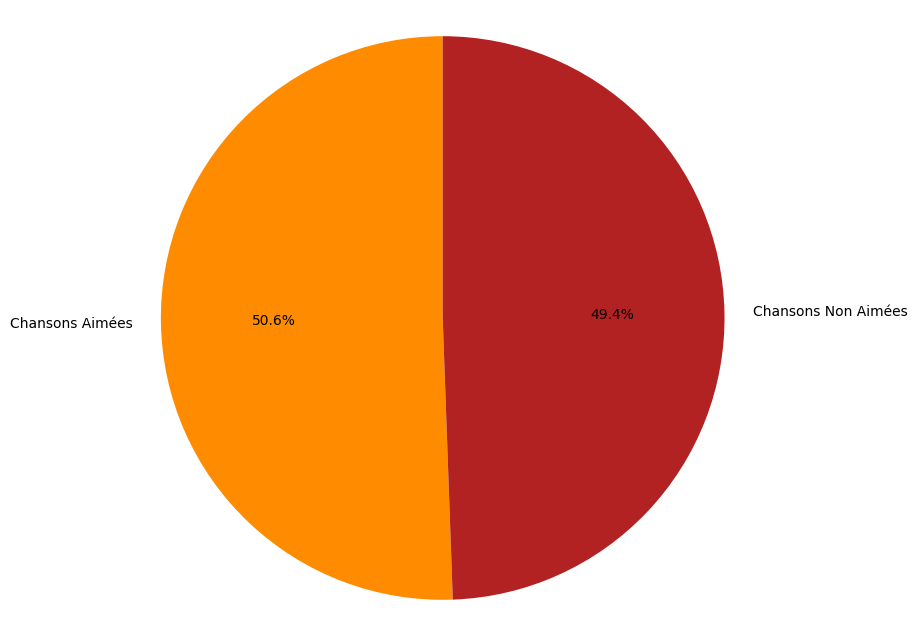

In [51]:
value_counts = df['target'].value_counts()
labels = ['Chansons Aimées', 'Chansons Non Aimées']
sizes = [value_counts.get(1, 0), value_counts.get(0, 0)]
colors = ['darkorange', 'firebrick']

plt.figure(figsize=(8, 8)) 
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.axis('equal') 

plt.show()
plt.close()

La distribution est presque parfaitement équilibrée, avec une légère prépondérance de chansons aimées.  
Cette quasi-parité (**écart de seulement 1,2%**) indique :

- Un jeu de données bien **équilibré**, idéal pour l'entraînement d'algorithmes de machine learning  
- **Absence de biais significatif** vers l'une ou l'autre catégorie
#### Pour un modèle de prédiction :

- Une distribution équilibrée permet d’obtenir des **résultats plus fiables**  
- Les **métriques de performance** (comme l’accuracy) seront **plus représentatives**, car il n’y a pas de **classe dominante** qui fausse les prédictions


### **3.2 Heatmap des corrélations**

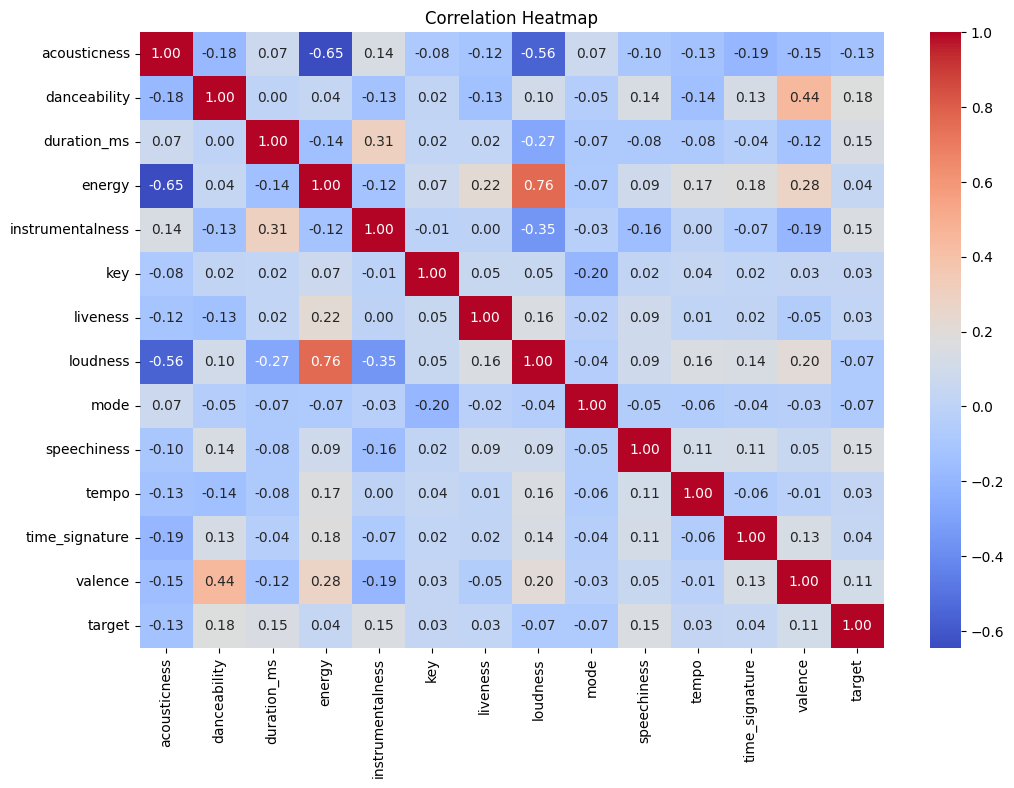

In [52]:
# Définir la taille de la figure pour la heatmap
plt.figure(figsize=(12, 8))

# Créer la heatmap des corrélations et on supprime les colonnes "song_title" et "artist" car elles ne sont pas numériques
sns.heatmap(df.drop(columns=["song_title", "artist"], axis=1, inplace=False).corr(), 
            annot=True, cmap="coolwarm", fmt='.2f')

# Ajouter un titre à la heatmap
plt.title("Correlation Heatmap")


# Afficher la heatmap à l'écran
plt.show()

#### **Corrélations les plus fortes (positives)**

| Variables liées                     | Corrélation | Interprétation                                                          |
| ----------------------------------- | ----------- | ----------------------------------------------------------------------- |
| *energy & loudness*               | *0.76*    | Plus une chanson est énergique, plus elle est forte (logique en audio). |
| *valence & danceability*          | *0.44*    | Les chansons "joyeuses" (valence) sont plus dansables.                  |
| *instrumentalness & duration\_ms* | *0.31*    | Les chansons plus longues ont tendance à être plus instrumentales.      |

---

#### **Corrélations les plus fortes (négatives)**

| Variables liées                 | Corrélation | Interprétation                                                |
| ------------------------------- | ----------- | ------------------------------------------------------------- |
| *energy & acousticness*       | *-0.65*   | Les morceaux acoustiques sont souvent moins "énergétiques".   |
| *loudness & acousticness*     | *-0.56*   | Les morceaux acoustiques sont moins forts (en volume sonore). |
| *loudness & instrumentalness* | *-0.35*   | Les morceaux instrumentaux sont souvent plus calmes.          |

---

#### **Corrélation avec la variable "target"**

| Variable                                          | Corrélation avec target | Observation                                                                                 |
| ------------------------------------------------- | ------------------------- | ------------------------------------------------------------------------------------------- |
| *danceability*                                  | *0.18*                  | Faible corrélation positive — les chansons dansables sont légèrement plus liées à la cible. |
| *duration\_ms / speechiness / instrumentalness* | *≈ 0.15*                | Corrélations faibles, mais positives.                                                       |
| *acousticness / loudness / energy*              | *< 0.1 ou négatif*      | Peu ou pas de lien significatif avec la cible.                                              |



---

#### **Conclusions**

- **Redondance possible**
    - **Energy** et **loudness** étant très corrélées (0.76), l'une pourrait être supprimée pour réduire la colinéarité dans un modèle de machine learning.

- **Relations logiques**
    - Les corrélations sont globalement **cohérentes** (par exemple, **acousticness** vs **loudness**, **valence** vs **danceability**).

- **Prédiction de target**
    - La variable **target** n'est fortement corrélée à *aucune* caractéristique individuelle. Cela peut indiquer :
        - Les facteurs influençant la popularité sont **complexes** (multivariés),
        - ou que **target** dépend d'autres variables non présentes ici.
    - Aucune variable seule ne permettrait une bonne prédiction. Il faudra :
       - Explorer des **interactions** ou des **transformations** de variables.


### **3.3 Pairplots**

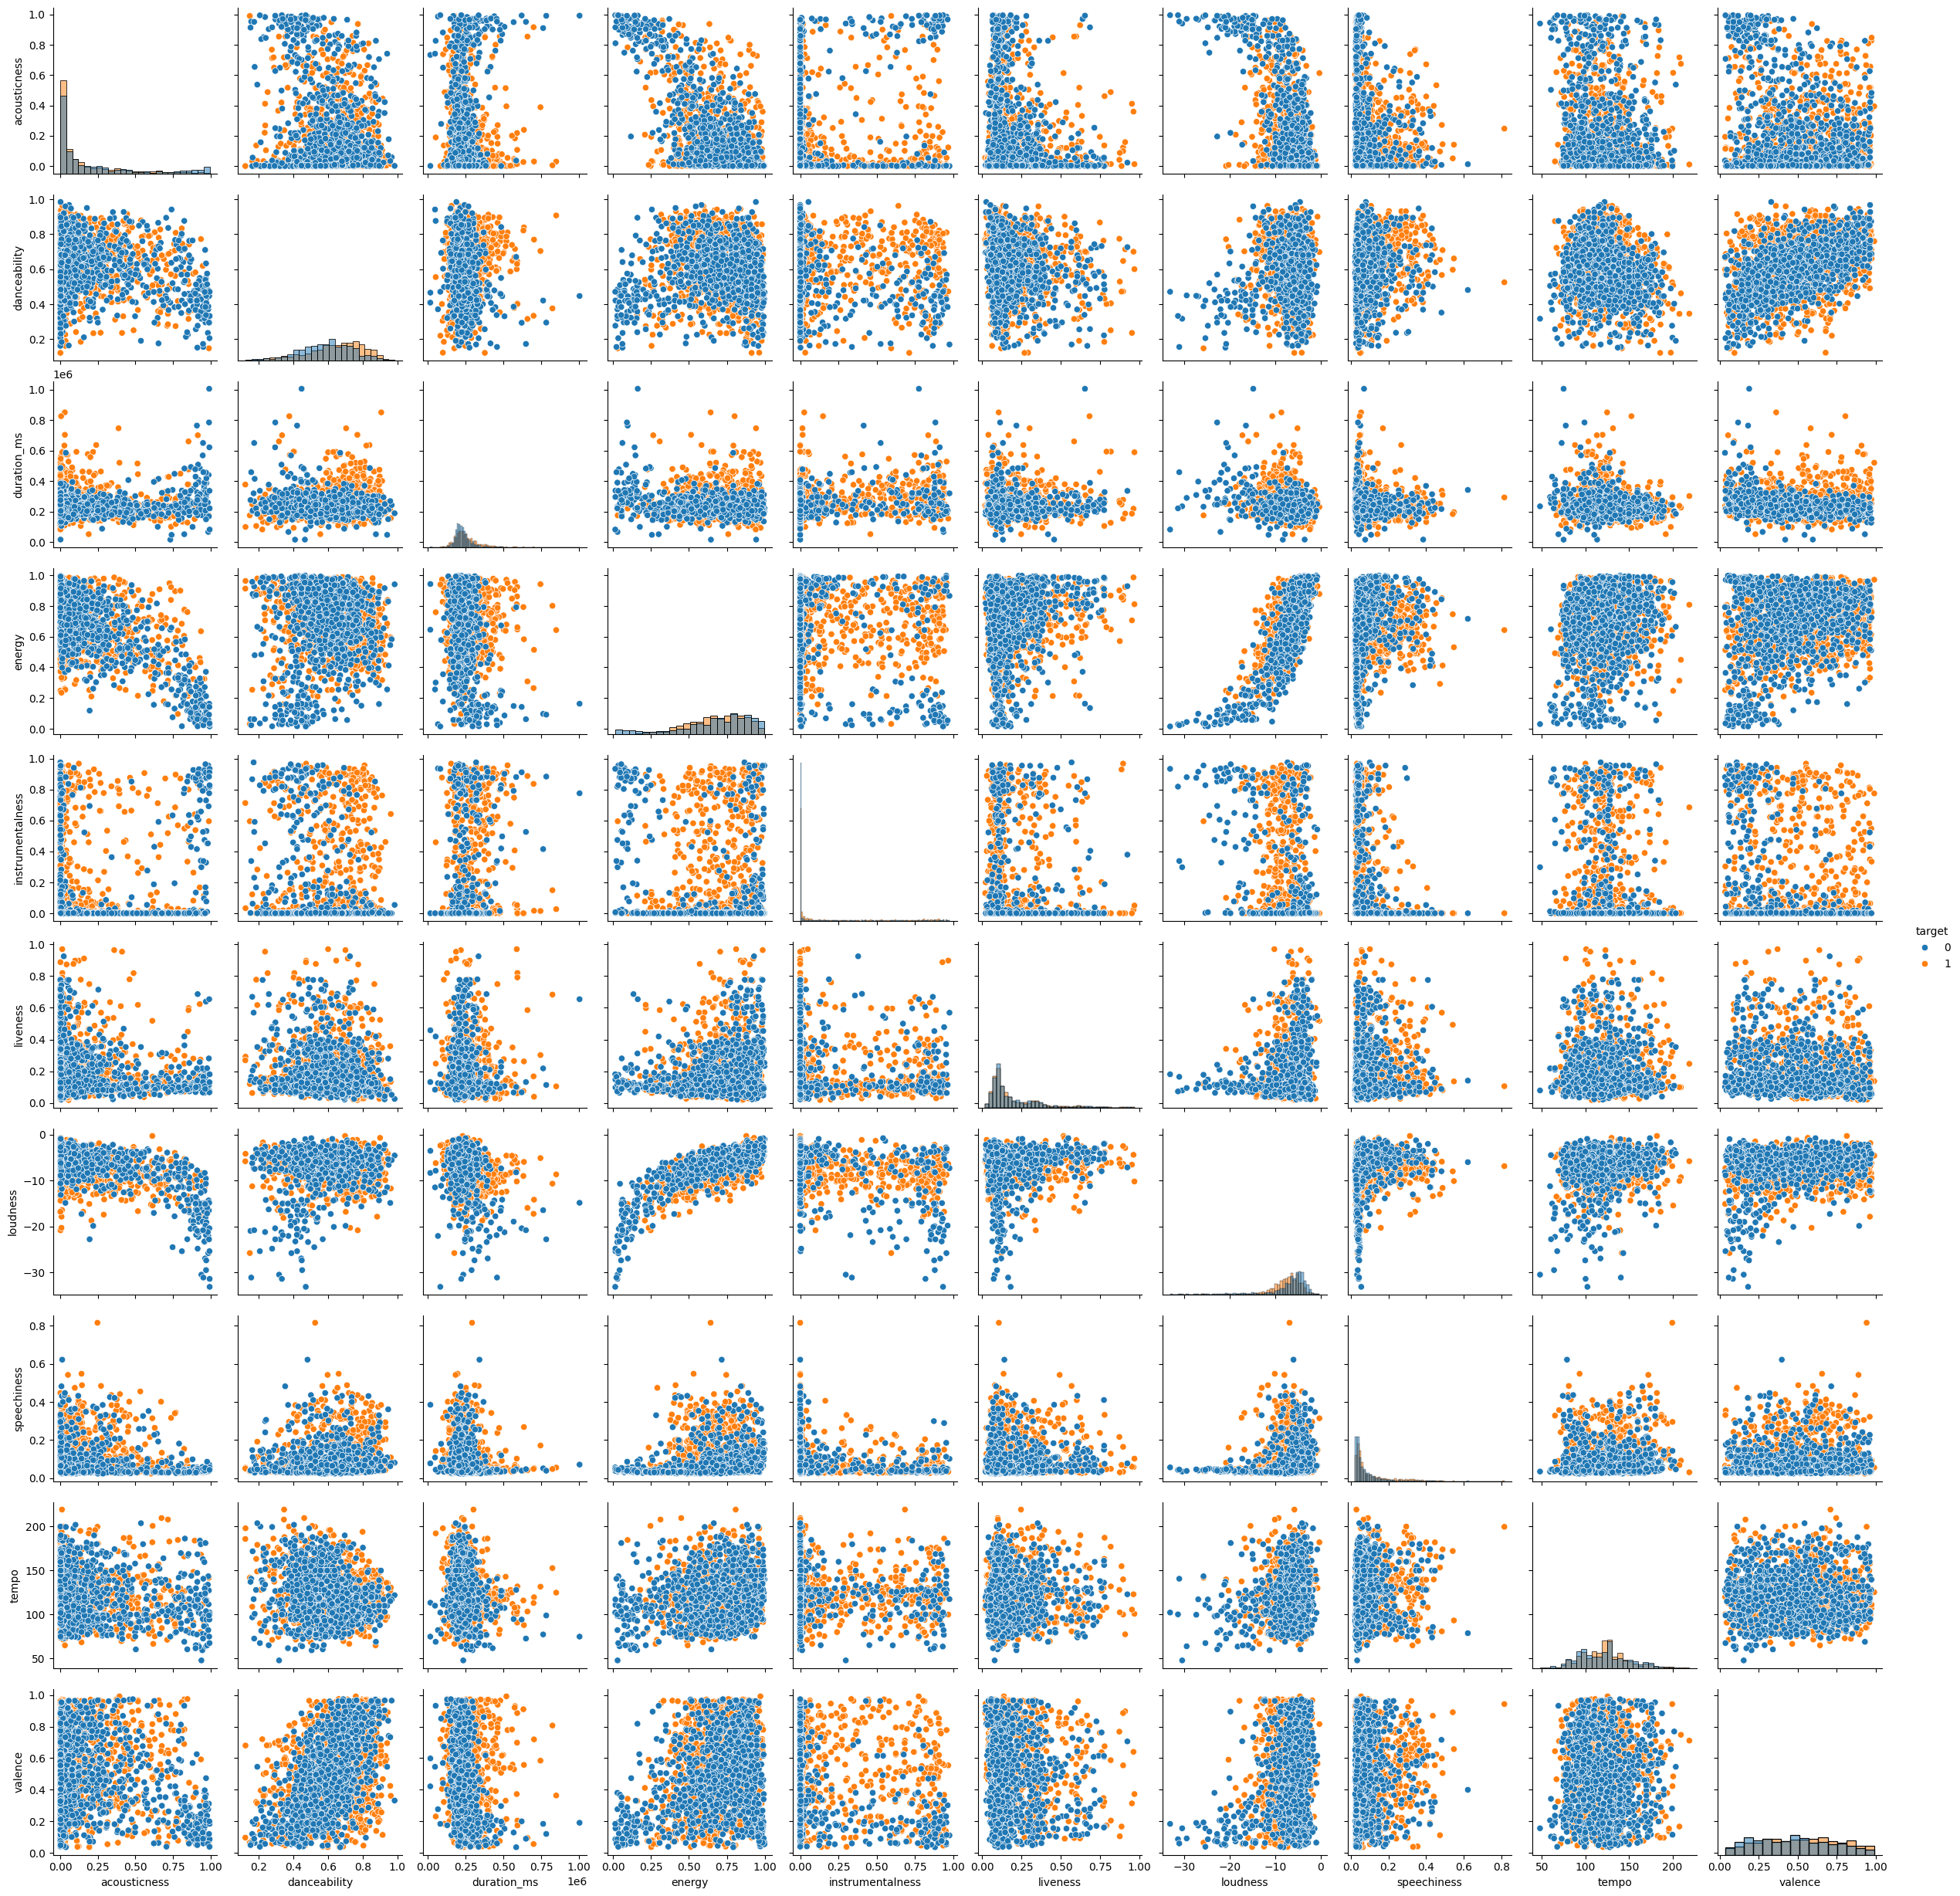

In [53]:
# Définition des features
cont_features = ['acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness',
                 'liveness', 'loudness', 'speechiness', 'tempo', 'valence']

# Création du pairplot
pairplot = sns.pairplot(df[cont_features + ['target']], hue='target', diag_kind='hist')

# Affichage du graphique
plt.show()

* *Variables discriminantes* : certaines variables montrent des différences marquées entre les classes (target = 0 et target = 1), notamment :

  * energy, loudness et instrumentalness (plus élevés pour la classe 1),
  * acousticness (plus élevé pour la classe 0),
  * valence (répartition différente entre les deux classes).

* *Corrélations importantes* :

  * Forte corrélation positive entre energy et loudness.
  * Corrélation négative entre acousticness et energy.
  * Cela indique une redondance potentielle qu’il conviendra de prendre en compte lors du choix des variables explicatives.

* *Variables moins pertinentes individuellement* :

  * tempo, speechiness, liveness et duration_ms montrent peu de variation entre les classes, ce qui limite leur pouvoir discriminant pris isolément.

#### **Conclusion :**

L’analyse visuelle met en évidence plusieurs variables prometteuses pour la classification. Toutefois, en raison de corrélations fortes entre certaines d’entre elles, une étape de sélection ou de transformation pourrait s’avérer nécessaire. Un modèle non linéaire pourrait également mieux capturer les relations complexes entre les variables.

### **3.4 Histograms des attributs**


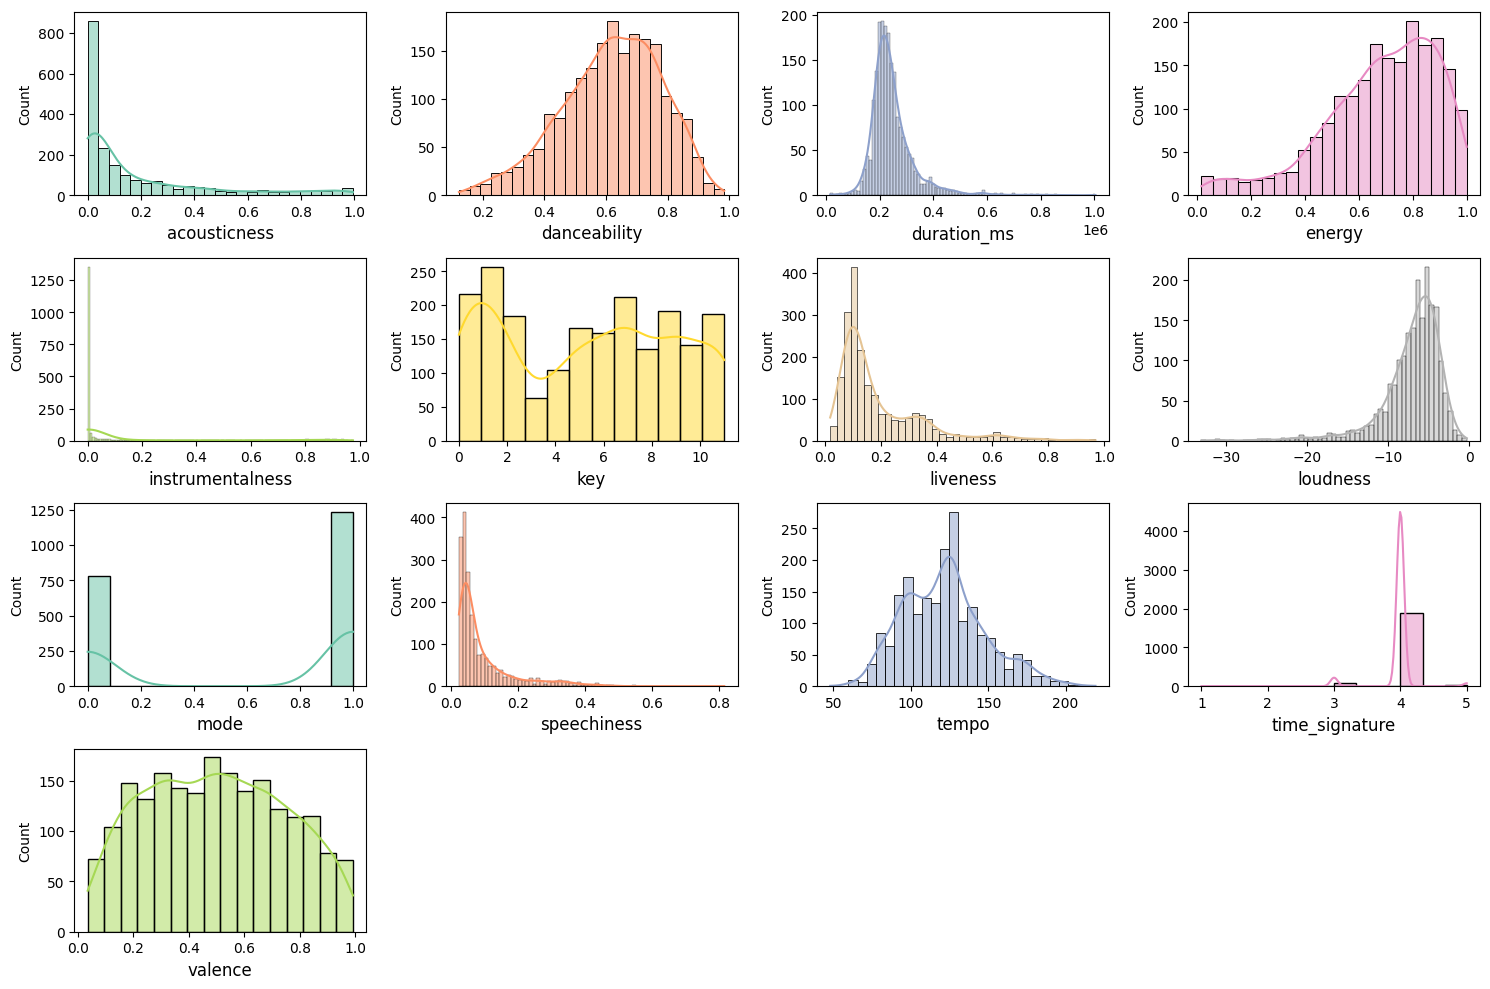

In [54]:
# Liste des variables (13 variables)
features = ['acousticness', 'danceability', 'duration_ms', 'energy',
            'instrumentalness', 'key', 'liveness', 'loudness', 'mode',
            'speechiness', 'tempo', 'time_signature', 'valence']

# Création de la figure et des axes pour 4x4 (16 sous-graphiques)
fig, ax = plt.subplots(4, 4, figsize=(15, 10))

# Générer une palette
color_palette = sns.color_palette("Set2", n_colors=len(features))

# Boucle pour chaque variable
for i, feature in enumerate(features):
    row = i // 4
    col = i % 4
    sns.histplot(x=df[feature], kde=True, ax=ax[row, col], color=color_palette[i])
    ax[row, col].set_xlabel(feature, fontsize=12)

# Supprimer les axes vides si nécessaire
for j in range(i + 1, 16):  # On a 16 cases, donc on masque celles restantes (3)
    row = j // 4
    col = j % 4
    ax[row, col].axis('off')

# Ajuster l'espacement entre les graphiques
plt.tight_layout()


plt.show()


### `acousticness`
- Distribution *très asymétrique à droite* (majorité proche de 0).
- La plupart des morceaux sont *peu acoustiques*.

### `danceability`
- Distribution *centrée autour de 0.6*, en forme de cloche.
- Semble relativement *normale*, bon candidat pour des modèles linéaires.

### `duration_ms`
- Distribution *asymétrique à droite*.
- La majorité des morceaux durent entre *2 et 4 minutes*.
- Une transformation logarithmique peut être utile.

### `energy`
- Distribution *asymétrique à gauche*, concentrée entre 0.6 et 1.
- Beaucoup de morceaux *énergétiques*.

### `instrumentalness`
- Distribution *fortement biaisée à gauche*, pics extrêmes vers 0.
- Très peu de morceaux *purement instrumentaux*.

### `key`
- Distribution *quasi-uniforme* entre les 12 tonalités.
- Pas de tonalité dominante → à encoder via *one-hot*.

### `liveness`
- Distribution *asymétrique à droite*, majorité < 0.3.
- Peu de morceaux *enregistrés en live*.

### `loudness`
- Distribution *centrée vers -5 dB*, légèrement asymétrique à droite.
- Variation *cohérente du volume sonore*.

### `mode`
- Distribution *bimodale forte* (pics à 0 et 1).
- Variable *binaire* : mineur (0) / majeur (1).

### `speechiness`
- Distribution *fortement biaisée à gauche*.
- Très peu de morceaux avec un *contenu très "parlé"*.

### `tempo`
- Distribution *légèrement multimodale, avec un pic autour de **120 BPM*.
- Typique des musiques *dansantes ou pop*.

### `time_signature`
- Distribution *extrêmement concentrée sur 4*.
- Peut être *simplifiée* (e.g., binaire : 4 vs. autres).

### `valence`
- Distribution *quasi-uniforme*.
- Répartition équilibrée entre morceaux *joyeux et tristes*.

---

#### **Conclusion**

* **Transformation** pour les variables très asymétriques :
  * acousticness, instrumentalness, speechiness, liveness, duration\_ms.
* **Variables à distribution proche normale** (bonnes pour modèles linéaires) :
  * danceability, loudness, tempo.
* **Variables catégorielles** à encoder :
  * key → one-hot
  * mode → binaire
  * time\_signature → peut être réduite
* **Stratégies de modélisation** :
  * Normalisation ou transformation (log/boxcox) avant application de modèles.
  * Réduction dimensionnelle (PCA/UMAP) pour clustering ou visualisation.
  * Binarisation possible pour certaines features extrêmes (instrumentalness > 0.9 → instrumental).



### **3.5. Analyse des caractéristiques audio (en lien avec le target)**

L’objectif est d’observer les différences entre les chansons aimées (target = 1) et non aimées (target = 0), en étudiant les distributions de chaque variable audio.

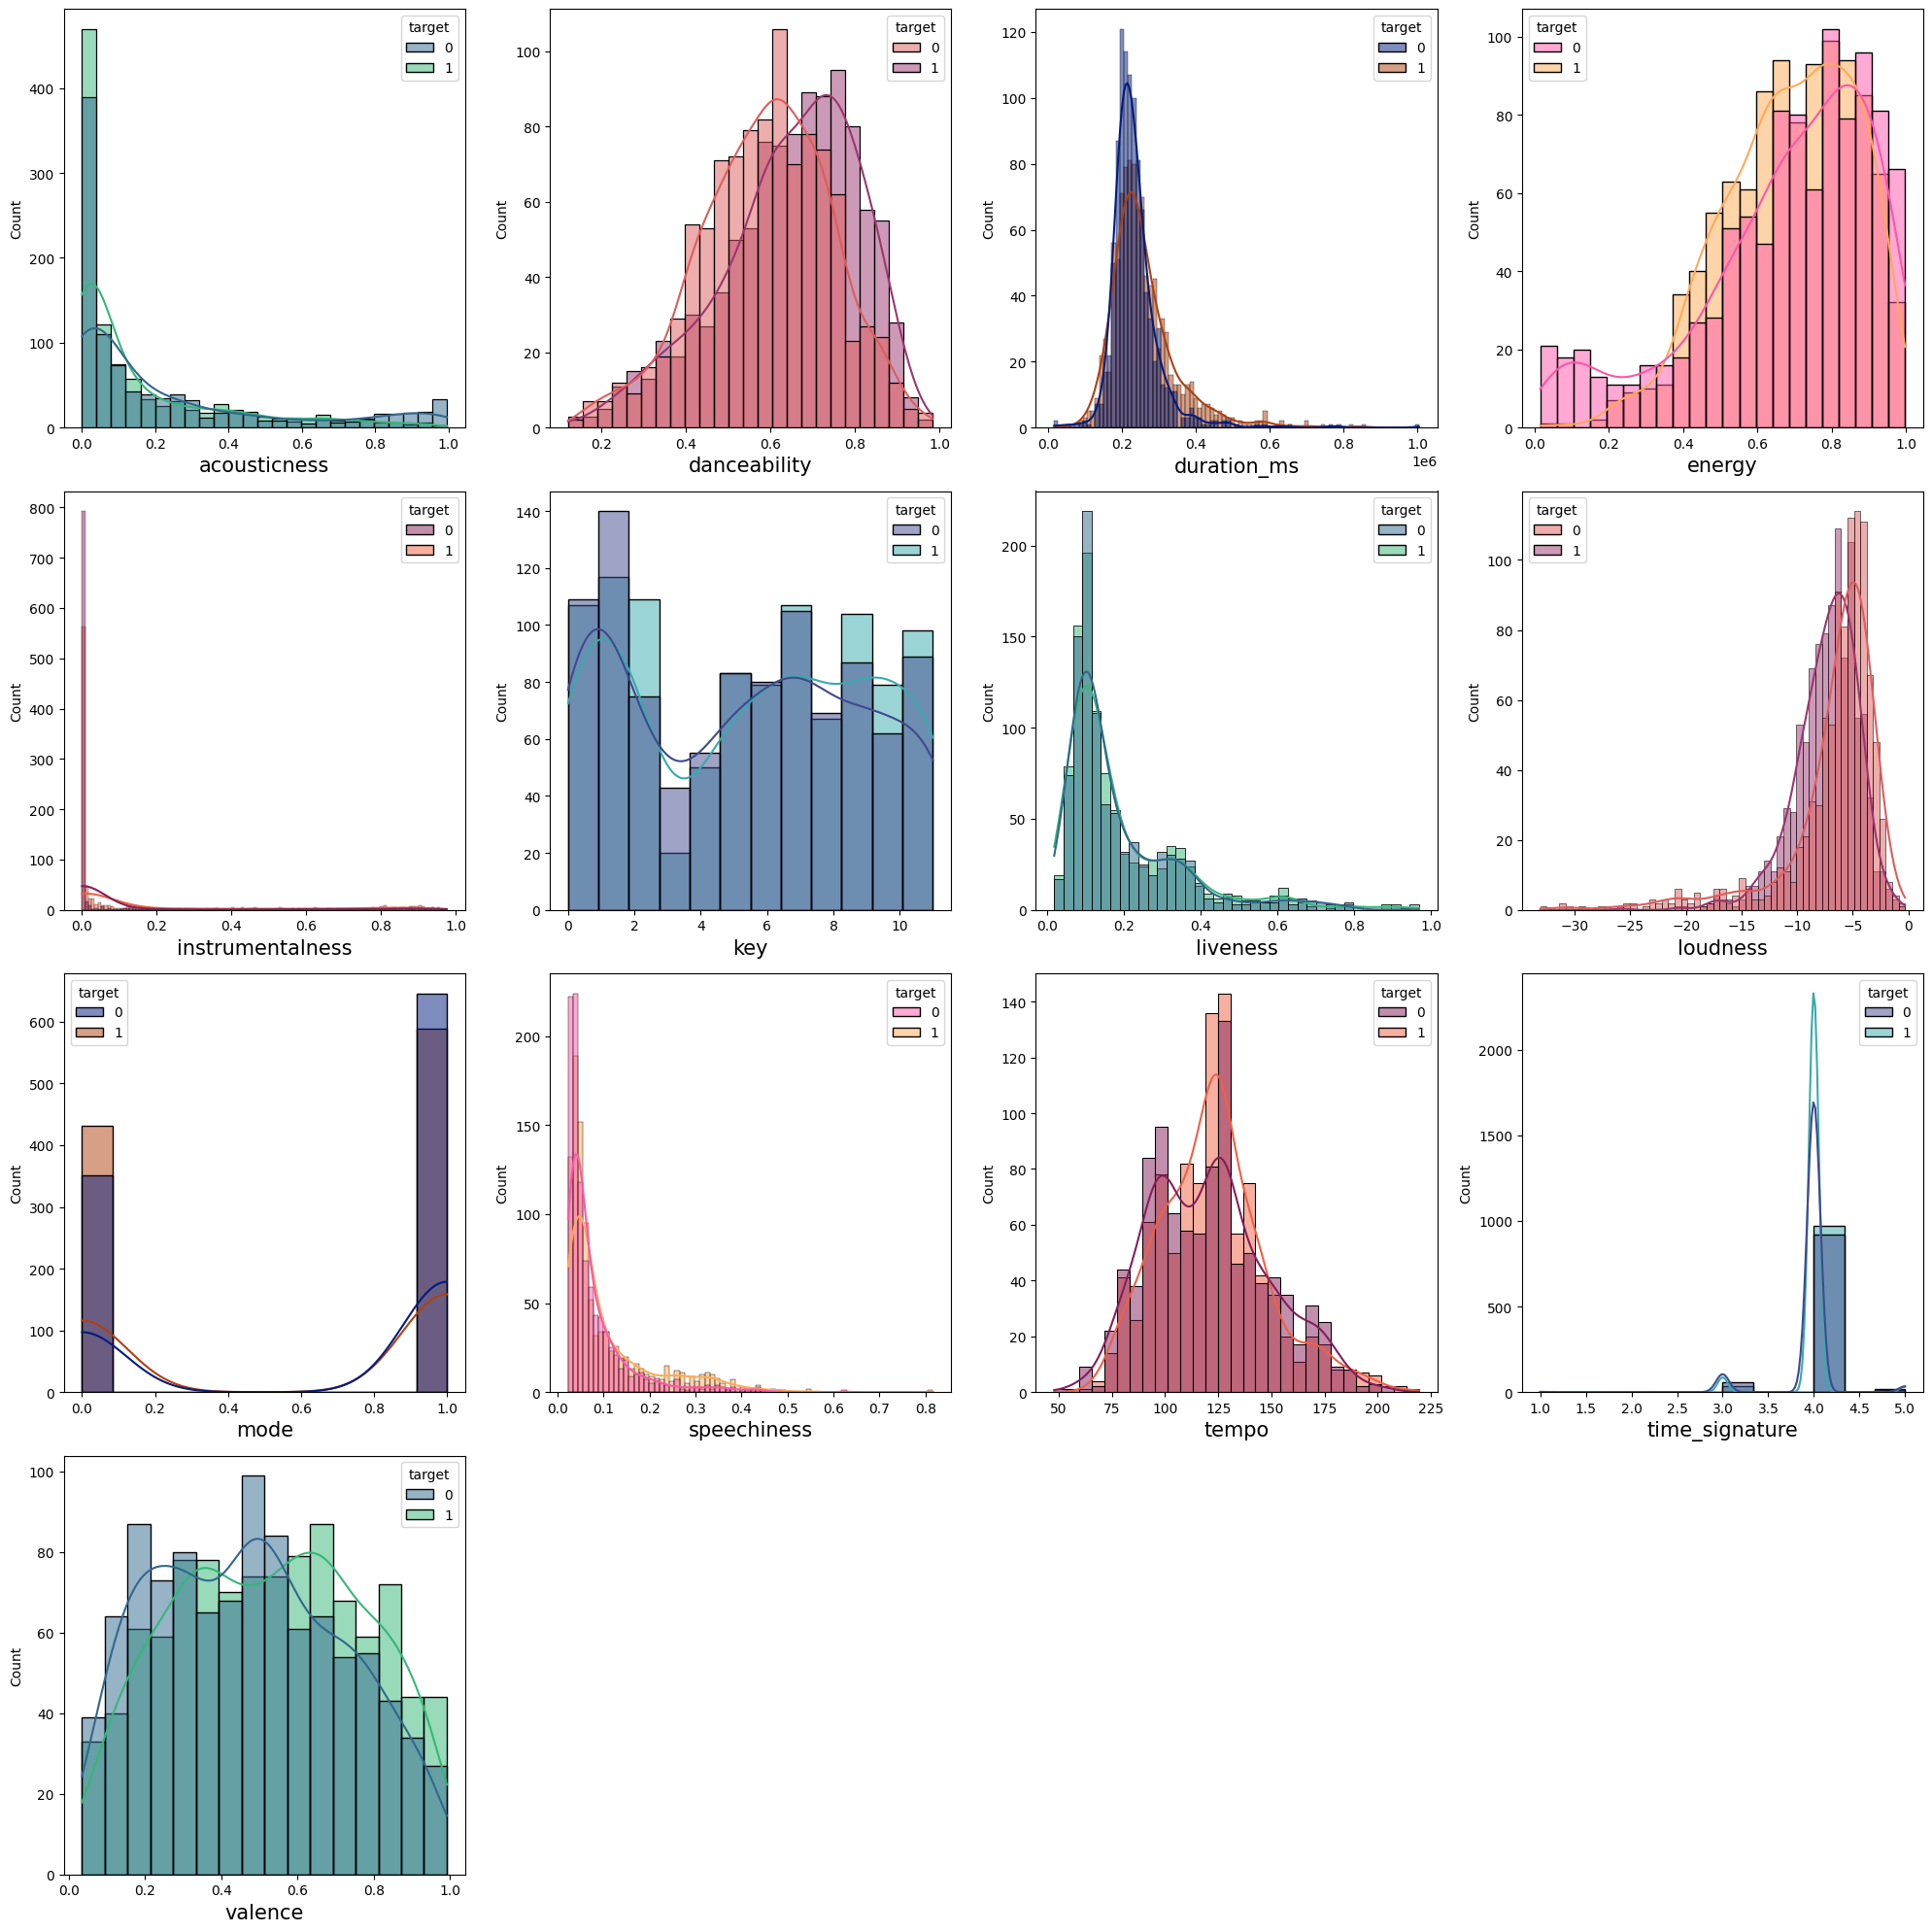

In [55]:
# Liste des variables 
features = ['acousticness', 'danceability', 'duration_ms', 'energy',
            'instrumentalness', 'key', 'liveness', 'loudness', 'mode',
            'speechiness', 'tempo', 'time_signature', 'valence']

# Créer un tableau de sous-graphiques 4x4 (16 sous-graphiques)
fig, ax = plt.subplots(4, 4, figsize=(20, 20))

# Liste de palettes de couleurs
colors = ["viridis", "flare", "dark", "spring", "rocket", "mako"]

# Boucle sur les variables pour afficher chaque histogramme, en ne remplissant que 13 cases
for i, feature in enumerate(features):
    x, y = i // 4, i % 4  # Calcul des positions dans la grille
    sns.histplot(x=df[feature], hue=df["target"], kde=True, ax=ax[x, y], palette=colors[i % len(colors)])
    ax[x, y].set_xlabel(feature, fontsize=15)

# Supprimer les axes vides
for i in range(13, 16):  # Index 13 à 15 (case vide) 
    ax[i // 4, i % 4].axis('off') 

# Ajuster l'espacement entre les graphiques
plt.tight_layout()

plt.show()

#### **Variables fortement asymétriques :** `acousticness`, `instrumentalness`, `speechiness`
- Ces variables sont *fortement concentrées vers 0*, avec quelques valeurs très élevées.
- Elles peuvent être *binarisées* pour une meilleure lisibilité et interprétabilité :
  - `acousticness` > 0.5 → chanson acoustique.
  - `instrumentalness` > 0.5 → chanson sans voix.
  - `speechiness` > 0.33 → contenu parlé (rap, podcast...).
- Cela simplifie leur usage dans un modèle sans perte d'information significative.

---

#### **Variables différenciantes utiles :** `danceability`, `energy`, `loudness`, `valence`
Ces variables montrent des *écarts clairs entre target = 0 et 1* :

- `Danceability` : les chansons aimées sont plus dansantes.
- `Energy` : elles sont plus énergiques (niveau d’intensité sonore élevé).
- `Loudness` : elles sont plus fortes en volume.
- `Valence` : les chansons aimées tendent à être plus positives (valence haute).

Elles peuvent être utilisées *telles quelles dans un modèle prédictif*.

---

#### **Variables partiellement informatives :** `tempo`, `duration_ms`, `liveness`
- `Tempo` : légère tendance à des BPM plus élevés pour les morceaux aimés, mais signal faible.
- `Duration_ms` : aucune différence claire ; à normaliser si utilisée.
- `Liveness` : utile uniquement dans les cas extrêmes (valeurs > 0.8).

---

#### **Variables peu discriminantes :** `key`, `mode`, `time_signature`
- `Key` : distribution relativement uniforme, sans impact clair.
- `Mode` : légère préférence pour le mode majeur (1) dans les chansons aimées.
- `Time_signature` : majorité en 4/4 pour tous les cas → peu utile seule.

Ces variables peuvent être *encodées* (one-hot ou binaire) si conservées.

---

#### **Conclusion**

| Type            | Variables                         | Traitement                                |
|-----------------|-----------------------------------|-------------------------------------------|
| *Continues*   | danceability, energy, loudness, valence | Utilisation directe                       |
| *Binarisées*  | acousticness, instrumentalness, speechiness | Seuils (> 0.5, > 0.33)                 |
| *À évaluer*   | tempo, liveness               | À normaliser ou transformer                |
| *Catégorielles*| key, mode, time_signature  | One-hot encoding ou binarisation simplifiée |

> Ce mélange de *variables continues* et *binarisées* est particulièrement adapté à des *modèles interprétables comme la régression logistique*, tout en conservant des performances intéressantes.

# **4. Analyse statistique**

### **4.1. Test du Chi² (vs target)**

In [235]:
# Discrétiser les variables continues en intervalles
def discretiser_colonnes(df, bins=4):
    df_binned = df.copy()  # Créer une copie du DataFrame pour ne pas modifier l'original
    # Sélectionner toutes les colonnes numériques, sauf la colonne cible
    colonnes_continues = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
    if 'target' in colonnes_continues:
        colonnes_continues.remove('target')  # Enlever 'target' si elle existe dans les colonnes
    for col in colonnes_continues:
        df_binned[col] = pd.qcut(df[col], q=bins, duplicates='drop')  # Discrétisation en bins
    return df_binned

# Effectuer le test du Chi-carré
def tests_chi_carre(df, target='target'):
    resultats = {}
    for col in df.columns:
        if col == target:
            continue  # Ignorer la colonne cible
        table_contingence = pd.crosstab(df[col], df[target])  # Créer la table de contingence
        chi2, p, dof, expected = chi2_contingency(table_contingence)  # Appliquer le test du Chi-carré
        resultats[col] = {'chi2_stat': chi2, 'p_value': p, 'dof': dof}
    return pd.DataFrame(resultats).T.sort_values(by='p_value')

df_binned = discretiser_colonnes(df)  
resultats = tests_chi_carre(df_binned)  
print(resultats)


                    chi2_stat       p_value     dof
instrumentalness   161.829343  7.231104e-36     2.0
loudness           119.372911  1.053145e-25     3.0
artist            1929.695058  5.833980e-24  1342.0
danceability        93.289786  4.303483e-20     3.0
duration_ms         75.200989  3.281170e-16     3.0
speechiness         44.833275  1.003922e-09     3.0
tempo               23.855636  2.677491e-05     3.0
valence             21.356474  8.877155e-05     3.0
acousticness        19.437238  2.219955e-04     3.0
energy              12.081016  7.110726e-03     3.0
liveness             4.203352  2.403265e-01     3.0
key                  4.164595  2.442306e-01     3.0
song_title        1990.996619  2.800074e-01  1955.0
time_signature       0.359580  5.487395e-01     1.0
mode                 0.000000  1.000000e+00     0.0


#### **Variables significatives (p < 0.05)**

| Variable         | p-value  |
| ---------------- | -------- |
| instrumentalness | 7.23e-36 |
| loudness         | 1.05e-25 |
| artist           | 5.83e-24 |
| danceability     | 4.30e-20 |
| duration\_ms     | 3.28e-16 |
| speechiness      | 1.00e-09 |
| tempo            | 2.68e-05 |
| valence          | 8.88e-05 |
| acousticness     | 2.22e-04 |
| energy           | 7.11e-03 |

---

#### **Variables non significatives (p ≥ 0.05)**

| Variable        | p-value |
| --------------- | ------- |
| liveness        | 0.240   |
| key             | 0.244   |
| song\_title     | 0.280   |
| time\_signature | 0.549   |
| mode            | 1.000   |

---

#### **Conclusion**

* *10 variables* ont un lien significatif avec la cible → à conserver.
* Les autres peuvent être *exclues* pour simplifier le modèle.


### **4.2. ANOVA**
L'objectif de cette analyse est d'explorer les attributs des chansons sur Spotify et leur influence sur la **popularité** des morceaux, mesurée par la variable **target**. L'ANOVA a été utilisée pour tester si les moyennes des variables continues diffèrent significativement entre les chansons aimées et non aimées.

In [236]:
# List of continuous variables
continuous_vars = ['acousticness', 'danceability', 'duration_ms', 'energy',
                   'instrumentalness', 'liveness', 'loudness',
                   'speechiness', 'tempo', 'valence']

anova_results = []

for var in continuous_vars:
    group_0 = df[df['target'] == 0][var]
    group_1 = df[df['target'] == 1][var]

    # Run one-way ANOVA
    f_stat, p_val = f_oneway(group_0, group_1)
    anova_results.append({'Variable': var, 'F-statistic': f_stat, 'p-value': p_val})

# Convert results to DataFrame and sort by p-value
anova_df = pd.DataFrame(anova_results).sort_values('p-value')
print(anova_df)


           Variable  F-statistic       p-value
1      danceability    64.946241  1.305175e-15
7       speechiness    48.952670  3.555419e-12
4  instrumentalness    48.037542  5.607713e-12
2       duration_ms    44.348558  3.533195e-11
0      acousticness    34.437089  5.134762e-09
9           valence    23.748996  1.183240e-06
6          loudness    10.500299  1.213000e-03
3            energy     3.178830  7.474861e-02
8             tempo     2.433669  1.189117e-01
5          liveness     1.401510  2.366105e-01


#### Variables significatives (p < 0.05)

| Variable         | F-statistique | p-value  | Conclusion                                                                   |
| ---------------- | ------------- | -------- | ---------------------------------------------------------------------------- |
| danceability     | 64.95         | 1.31e-15 | Préférence nette pour les chansons plus dansantes.                           |
| speechiness      | 48.95         | 3.56e-12 | Les chansons contenant davantage de paroles sont plus populaires.            |
| instrumentalness | 48.04         | 5.61e-12 | Les chansons instrumentales présentent une différence marquée de popularité. |
| duration\_ms     | 44.35         | 3.53e-11 | Préférence pour des durées spécifiques (ni trop courtes ni trop longues).    |
| acousticness     | 34.44         | 5.13e-09 | Les morceaux plus acoustiques sont mieux perçus.                             |

#### Variables non significatives (p > 0.05)

| Variable | F-statistique | p-value | Conclusion                                       |
| -------- | ------------- | ------- | ------------------------------------------------ |
| energy   | 3.18          | 0.0747  | Pas de lien significatif avec la popularité.     |
| tempo    | 2.43          | 0.1189  | Aucun impact clair observé.                      |
| liveness | 1.40          | 0.2366  | L’ambiance live ne joue pas un rôle déterminant. |

---

### **Conclusion**

Certaines variables musicales influencent significativement la popularité des chansons sur Spotify, notamment *danceability*, *speechiness*, *acousticness*, *instrumentalness* et *duration\_ms*. Ces éléments peuvent guider l’optimisation de notre modèle de prédiction. Il serait pertinent d'inclure ces variables significatives dans le modèle prédictif pour aller plus loin.

---


# **5. Préparation des données**

### **5.1 Variables retenues**

In [57]:
# Conserver les variables avec p-value < 0.05
selected_num_vars = ['acousticness', 'danceability', 'duration_ms', 'instrumentalness', 'loudness', 'speechiness', 'valence'] 
selected_cat_vars = ['key', 'mode']  

### **5.2 Normalisation**

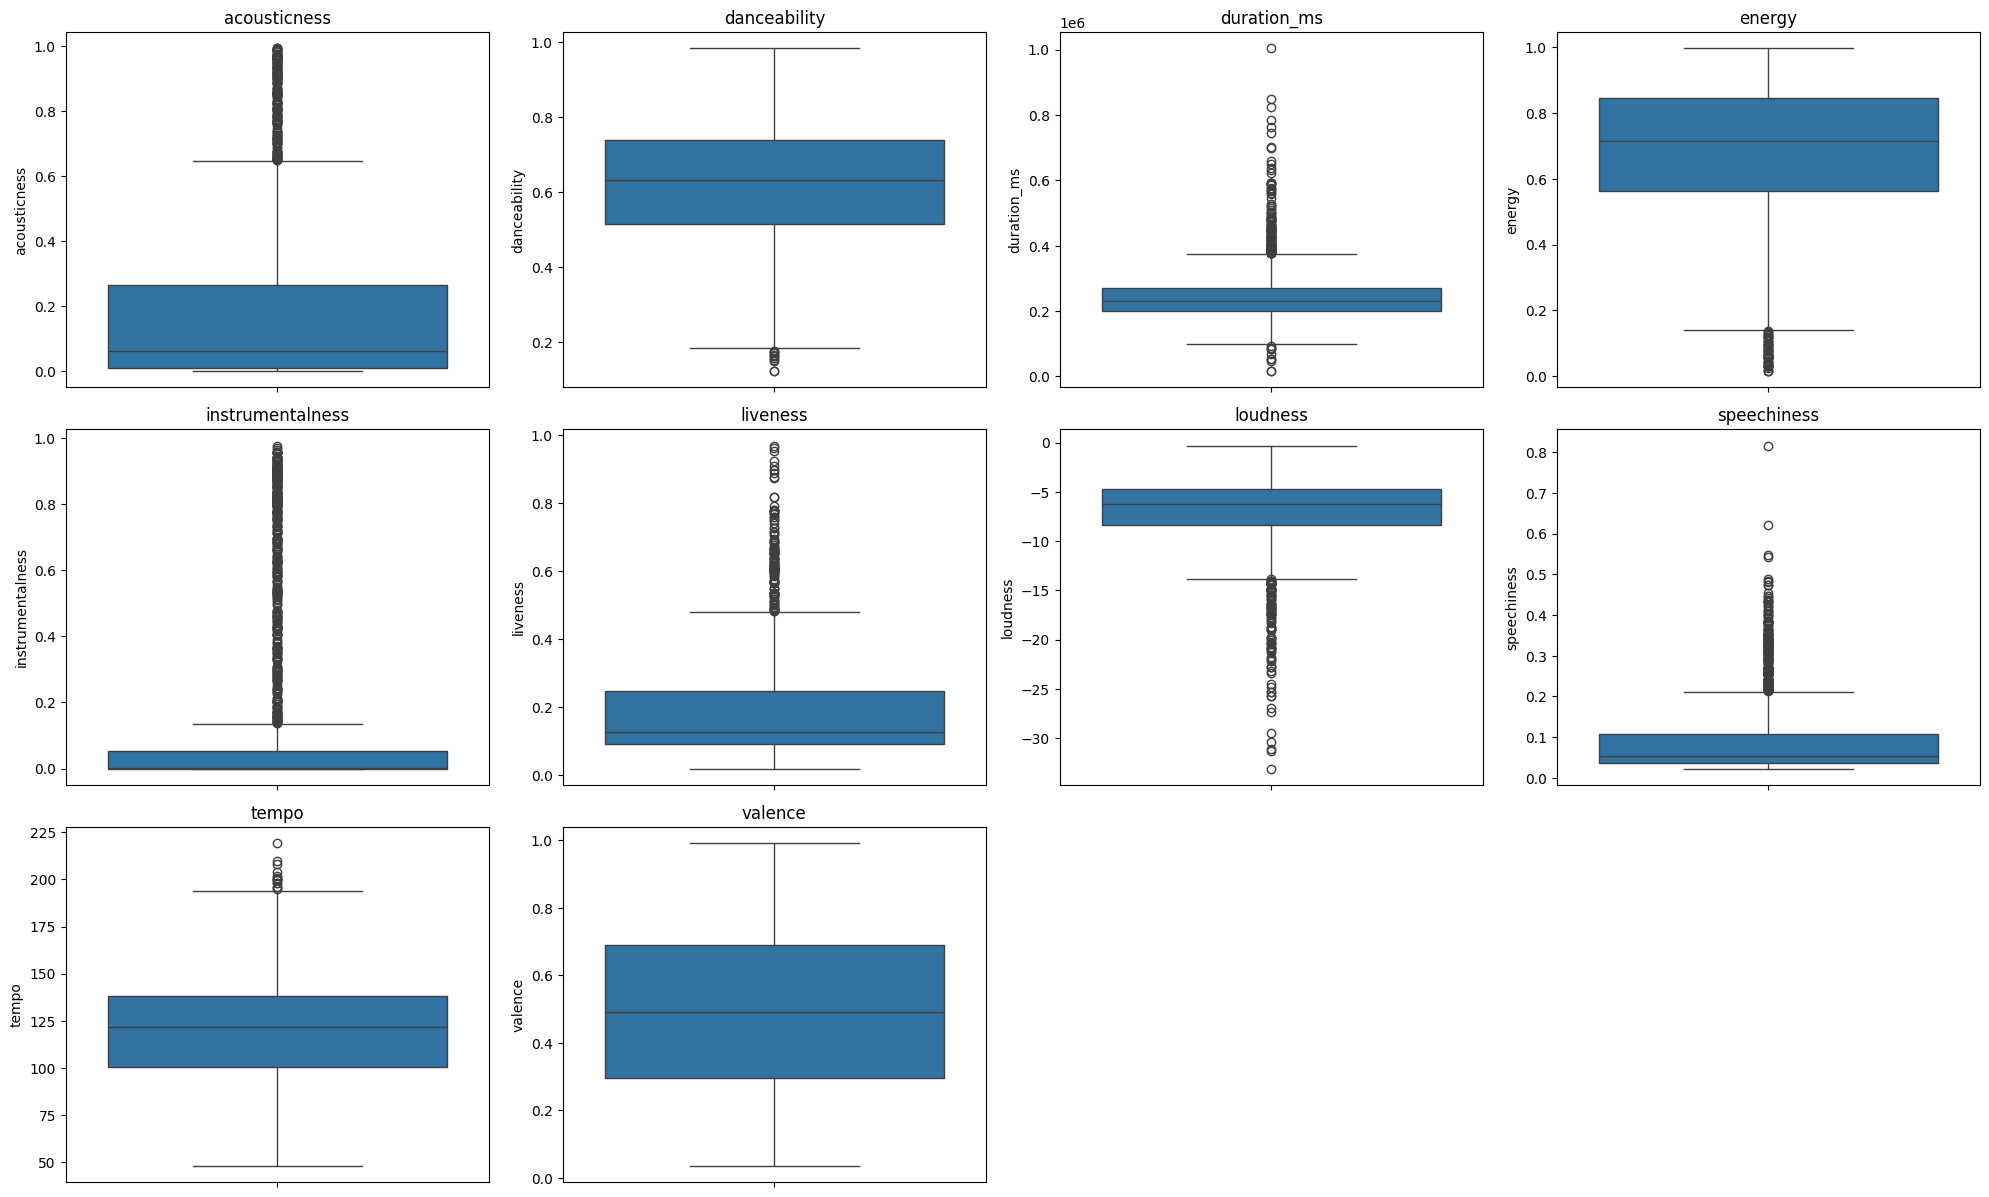

In [56]:
# Créer une figure avec 4x4 sous-graphes pour afficher les boxplots
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()  # Aplatir les axes pour une itération facile

# Boucle sur chaque caractéristique continue et affichage du boxplot correspondant
for i, col in enumerate(cont_features):
    sns.boxplot(y=df[col], ax=axes[i])  # Tracer le boxplot pour chaque caractéristique
    axes[i].set_title(col)  # Définir le titre du graphique pour chaque caractéristique

# Supprimer les axes vides restants si le nombre de caractéristiques est inférieur à 16
for j in range(len(cont_features), len(axes)):
    fig.delaxes(axes[j])

# Ajuster la mise en page pour éviter le chevauchement
plt.tight_layout()


# Afficher la figure
plt.show()

L'analyse des boxplots montre que :

* Plusieurs variables comme duration_ms, tempo, instrumentalness ou speechiness présentent des *outliers notables* (morceaux très longs, très rapides ou très parlés).
* Les échelles des variables sont *hétérogènes* : duration_ms est en millisecondes, loudness est en décibels négatifs, tandis que d'autres variables comme danceability, valence, energy ou acousticness sont normalisées entre 0 et 1.
* Certaines distributions sont *asymétriques*, notamment instrumentalness, speechiness et acousticness, qui sont très concentrées vers 0 avec de rares valeurs élevées.

---

#### Pour le prétraitement:

Afin de garantir une base propre pour la modélisation, les étapes suivantes seront abordées par la suit:

*  *Transformation logarithmique* sur les variables à longue traîne (instrumentalness, speechiness, tempo, duration_ms) pour réduire l’asymétrie.
*  *Mise à l’échelle des variables* :

  * RobustScaler est adapté pour limiter l’influence des outliers tout en normalisant les données.
  * Alternativement, StandardScaler peut être utilisé si les outliers sont filtrés.

In [58]:
# Définition des scalers
scalers = {
    'acousticness': RobustScaler(),  # Utilisation de RobustScaler pour réduire l'impact des outliers sur 'acousticness'
    'danceability': StandardScaler(),  # StandardScaler est adapté pour centrer et réduire les valeurs de 'danceability'
    'duration_ms': RobustScaler(),  # 'duration_ms' peut avoir des valeurs extrêmes, donc RobustScaler est utilisé
    'instrumentalness': RobustScaler(),  # 'instrumentalness' pourrait également avoir des valeurs extrêmes, d'où l'utilisation de RobustScaler
    'loudness': StandardScaler(),  # Pour 'loudness', StandardScaler est utilisé pour obtenir une distribution standardisée
    'speechiness': RobustScaler(),  # 'speechiness' peut également contenir des valeurs aberrantes, donc on applique RobustScaler
    'valence': StandardScaler()  # 'valence' suit une distribution plus normale, ce qui justifie l'utilisation de StandardScaler
}

# Création d'un nouveau DataFrame df_scaled avec les valeurs mises à l'échelle
df_scaled = df.copy()

# Application du scaler correspondant à chaque colonne
for column, scaler in scalers.items():
    df_scaled[column] = scaler.fit_transform(df[[column]])
df_scaled.head()

,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,target,song_title,artist
0,-0.207934,1.332874,-0.350707,0.434,0.404144,2,0.1650,-0.454530,1,5.334752,150.062,4,-0.853039,1,Mask Off,Future
1,0.531386,0.773830,1.389004,0.359,0.111737,1,0.1370,-0.881573,1,0.347518,160.083,4,0.368970,1,Redbone,Childish Gambino
2,-0.113169,1.363932,-0.619386,0.412,0.002922,2,0.1590,-0.016586,1,3.320567,75.044,4,-1.310280,1,Xanny Family,Future
3,2.117320,-0.772860,-0.424472,0.338,9.443033,5,0.0922,-2.167220,1,-0.408511,86.468,4,-1.079636,1,Master Of None,Beach House
4,0.456984,0.370075,2.327029,0.561,9.480070,5,0.4390,-1.213155,0,0.205674,174.004,4,1.647627,1,Parallel Lines,Junior Boys


### **5.3. Encodage**

In [62]:
df_encoded = pd.get_dummies(df_scaled, columns=['key','mode'])
df_encoded.columns

Index(['acousticness', 'danceability', 'duration_ms', 'energy',
       'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo',
       'time_signature', 'valence', 'target', 'song_title', 'artist', 'key_0',
       'key_1', 'key_2', 'key_3', 'key_4', 'key_5', 'key_6', 'key_7', 'key_8',
       'key_9', 'key_10', 'key_11', 'mode_0', 'mode_1'],
      dtype='object')

* **`key`** : codée de 1 à 12 sans ordre significatif → *one-hot* évite une fausse hiérarchie.
* **`mode`** : *one-hot* évite d’induire une relation d’ordre implicite.

### **5.4 Split**

In [63]:
X = df_encoded.drop(columns=["target","artist",'song_title'])
y = df_encoded['target']

In [64]:
# Séparation des données en ensembles d'entraînement et de test (75% / 25%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# **6. Modélisation et évaluation**


--- Régression Logistique ---
Confusion Matrix :
 [[159  82]
 [ 81 183]]
Classification Report :
               precision    recall  f1-score   support

           0       0.66      0.66      0.66       241
           1       0.69      0.69      0.69       264

    accuracy                           0.68       505
   macro avg       0.68      0.68      0.68       505
weighted avg       0.68      0.68      0.68       505

AUC Score : 0.712


*********************************************



--- Random Forest ---
Confusion Matrix :
 [[188  53]
 [ 61 203]]
Classification Report :
               precision    recall  f1-score   support

           0       0.76      0.78      0.77       241
           1       0.79      0.77      0.78       264

    accuracy                           0.77       505
   macro avg       0.77      0.77      0.77       505
weighted avg       0.77      0.77      0.77       505

AUC Score : 0.852


*********************************************



--- Gradient Boosti

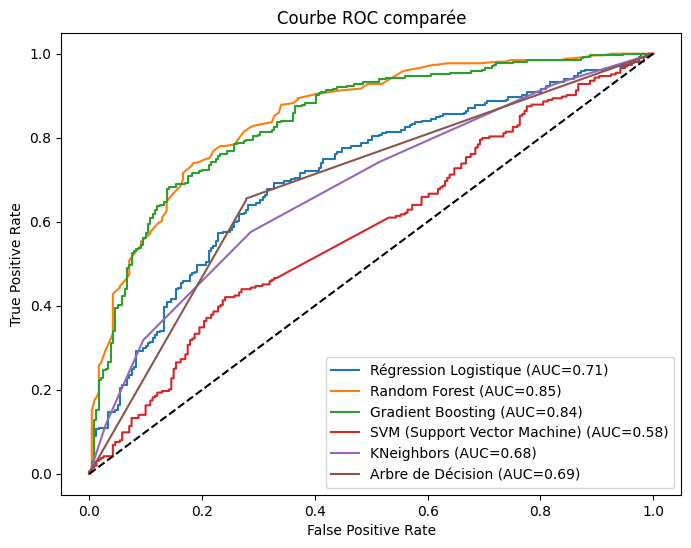

In [68]:
# Initialisation de la figure pour la courbe ROC
plt.figure(figsize=(8, 6))

# Define your models in a dictionary
models = {
    "Régression Logistique": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM (Support Vector Machine)": SVC(probability=True, random_state=42),
    "KNeighbors": KNeighborsClassifier(),
    "Arbre de Décision": DecisionTreeClassifier(random_state=42)
}


# Boucle d'entraînement et d'évaluation des modèles
for name, model in models.items():
    print(f"\n--- {name} ---")
    
    # Entraînement du modèle
    model.fit(X_train, y_train)
    
    # Prédiction des classes et probabilités
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    # Évaluation des performances du modèle
    print("Confusion Matrix :\n", confusion_matrix(y_test, y_pred))
    print("Classification Report :\n", classification_report(y_test, y_pred))
    
    # Calcul du score AUC
    auc = roc_auc_score(y_test, y_proba)
    print(f"AUC Score : {auc:.3f}")
    
    # Tracé de la courbe ROC
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.2f})")

    print("\n\n*********************************************\n\n")

# Configuration finale du graphique
plt.plot([0, 1], [0, 1], 'k--')  # Ligne diagonale
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Courbe ROC comparée')
plt.legend(loc='lower right')

# Sauvegarde de la figure
plt.show()


Plusieurs modèles ont été testés pour prédire la variable cible. La comparaison des courbes ROC met en évidence les performances discriminantes de chacun, mesurées par l’AUC (Area Under Curve).

#### **Résultats :**

| Modèle                    | AUC      | Interprétation                                    |
| ------------------------- | -------- | ------------------------------------------------- |
| *Random Forest*         | *0.85* | Meilleur score, très bonne capacité de classement |
| *Gradient Boosting*     | 0.84     | Excellente performance, proche de Random Forest   |
| *Régression Logistique* | 0.71     | Moyenne, mais interprétable                       |
| *KNeighbors*            | 0.68     | Modeste, sensible au choix de k                 |
| *Arbre de Décision*     | 0.69     | Correct mais inférieur à Random Forest            |
| *SVM (linéaire)*        | 0.58     | Faible performance, proche du hasard              |

#### **Conclusion :**

* Les modèles *ensemble* (Random Forest et Gradient Boosting) offrent les *meilleurs résultats*.
* La *régression logistique* reste une base simple et interprétable.
* Le *SVM* sous-performe dans ce contexte, probablement dû à une non-linéarité mal captée.

# **7. Tuning**


.. Tuning de : Régression Logistique
.. Meilleurs paramètres : {'model__C': 0.01}
Confusion Matrix :
 [[165  76]
 [ 95 169]]
Classification Report :
               precision    recall  f1-score   support

           0       0.63      0.68      0.66       241
           1       0.69      0.64      0.66       264

    accuracy                           0.66       505
   macro avg       0.66      0.66      0.66       505
weighted avg       0.66      0.66      0.66       505

AUC Score : 0.701


*********************************************



.. Tuning de : Random Forest
.. Meilleurs paramètres : {'model__max_depth': None, 'model__n_estimators': 200}
Confusion Matrix :
 [[189  52]
 [ 61 203]]
Classification Report :
               precision    recall  f1-score   support

           0       0.76      0.78      0.77       241
           1       0.80      0.77      0.78       264

    accuracy                           0.78       505
   macro avg       0.78      0.78      0.78       505
wei

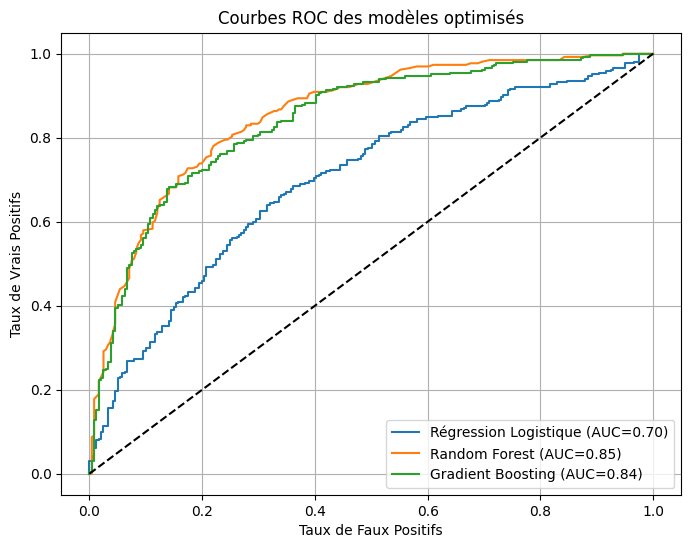

In [69]:
# Paramètres à tester pour le tuning des modèles
param_grid = {
    "Régression Logistique": {
        'model__C': [0.01, 0.1, 1, 10]
    },
    "Random Forest": {
        'model__n_estimators': [100, 200],
        'model__max_depth': [None, 5, 10]
    },
    "Gradient Boosting": {
        'model__n_estimators': [100, 200],
        'model__learning_rate': [0.01, 0.1, 0.2]
    }
}

# Modèles de base pour le pipeline
base_models = {
    "Régression Logistique": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

# Dictionnaire pour stocker les meilleurs modèles après tuning
best_models = {}

# Tuning et évaluation des modèles
plt.figure(figsize=(8, 6))

for name, model in base_models.items():
    print(f"\n.. Tuning de : {name}")
    pipe = Pipeline([("model", model)])
    grid = GridSearchCV(pipe, param_grid[name], cv=5, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train, y_train)

    print(f".. Meilleurs paramètres : {grid.best_params_}")
    best_model = grid.best_estimator_
    best_models[name] = best_model

    # Évaluation du modèle
    y_pred = best_model.predict(X_test)
    y_proba = best_model.predict_proba(X_test)[:, 1]

    print("Confusion Matrix :\n", confusion_matrix(y_test, y_pred))
    print("Classification Report :\n", classification_report(y_test, y_pred))
    auc = roc_auc_score(y_test, y_proba)
    print(f"AUC Score : {auc:.3f}")

    # Tracé de la courbe ROC
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.2f})")
    print("\n\n*********************************************\n\n")

# Tracé final de la courbe ROC
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbes ROC des modèles optimisés")
plt.legend()
plt.grid()
plt.show()


#### **Résultats après tuning**

* *Régression Logistique* (C=0.01) : AUC = 0.701, précision = 66 %. Modèle de base, interprétable mais limité.
* *Random Forest* (n_estimators=200) : *meilleur résultat, AUC = **0.855*, précision = 78 %.
* *Gradient Boosting* (learning_rate=0.1) : AUC = 0.842, précision = 76 %, proche de la Random Forest.

*Conclusion* : La *Random Forest* est retenue comme modèle final pour ses performances supérieures après tuning.


# **8. Modèle final**

AUC Score: 0.848
Confusion Matrix:
 [[191  50]
 [ 65 199]]


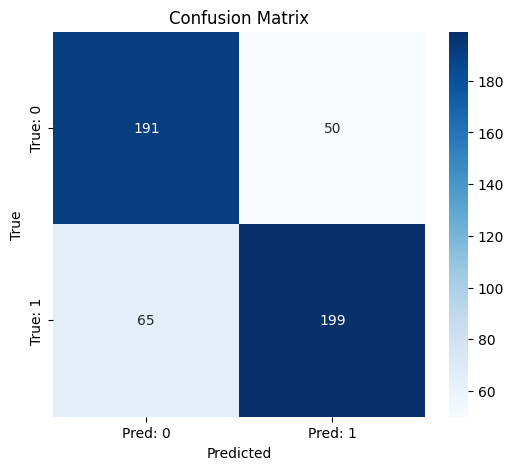

In [70]:
# Création et entraînement du modèle Random Forest
model = RandomForestClassifier()
model.fit(X_train, y_train)

# Prédiction des classes et des probabilités
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

# Calcul du score AUC
auc = roc_auc_score(y_test, y_proba)
print(f"AUC Score: {auc:.3f}")

# Calcul de la matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", conf_matrix)

# Affichage de la matrice de confusion sous forme de heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred: 0', 'Pred: 1'], yticklabels=['True: 0', 'True: 1'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# **9. Synthèse**

L'analyse des attributs musicaux sur Spotify révèle que la popularité des chansons est principalement influencée par:

- **Instrumentalness** (p=7.23e-36): les morceaux moins instrumentaux sont favorisés
- **Loudness** (p=1.05e-25): volume sonore fortement corrélé au succès
- **Danceability** (p=4.30e-20): préférence pour les chansons dansantes
- **Duration_ms** (p=3.28e-16): impact significatif de la durée
- **Speechiness** (p=1.00e-09): les chansons avec plus de paroles sont plus populaires

La méthodologie a impliqué une analyse de variance (ANOVA), des tests d'hypothèses multiples et une standardisation des données pour gérer les outliers et l'asymétrie des distributions. La forte colinéarité entre certaines variables a nécessité une approche prudente dans la sélection des prédicteurs.

Le modèle Random Forest offre les meilleures performances prédictives (AUC=0.855, précision=78%), suivi par Gradient Boosting (AUC=0.842) et Régression Logistique (AUC=0.701).

## Perspectives

Cette étude ouvre des pistes pour approfondir la compréhension des facteurs de succès musical. L'intégration d'autres variables contextuelles comme les tendances saisonnières, l'impact des réseaux sociaux ou les facteurs culturels pourrait enrichir le modèle prédictif. De plus, l'utilisation d'algorithmes plus avancés comme le deep learning pourrait permettre de capturer des interactions plus complexes entre les attributs musicaux. La question reste ouverte quant à l'évolution temporelle de ces facteurs d'influence et leur variabilité selon les genres musicaux ou les marchés géographiques.